<a href="https://colab.research.google.com/github/ayoadeoluwole98-CHE/CSTR-simulation-and-PID-control-for-Leaching/blob/main/Leaching_CSTR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cobalt leaching from Co(OH)2 in a cstr reactor. This includes the temperature control, and level control models with a PI controller  

# Leaching Process Design
 Cobalt leaching and precipitation: process simulation and reactor control

Based on: [Leaching and Impurity Washing of Cobalt Materials using Continuous Flow-through Micro
Reactors](https://doria.fi/handle/10024/195333$0)
---

## 1. Process overview
leaching with H2SO4, Na2CO3 precipitation of CoCO3, solid seperator and waste streams

## 2. DWSIM flowsheet
100m^3 and filled up to 60m^3 at 0.006m^3/s flow. Package: NRTL. Na2CO3 added as Na2CO3.2Na2SO4


## 3. Reactor model and control
model control for the reactor Temperature, concentration, and volume using a PID controller.

CV and MV:  temperature PI (jacket temperature), level PI (outlet flow), tuning values

[View Simulation File](https://drive.google.com/file/d/1s1zuJk5pOTS-z3P6YPg21ol4e6AInqfq/view?usp=sharing)


Co Leaching simulation 1.svg






## Author and notes
Oluwole Ayoade.

In [4]:
!pip install simple-pid gekko

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.7/14.7 MB 30.6 MB/s  0:00:00


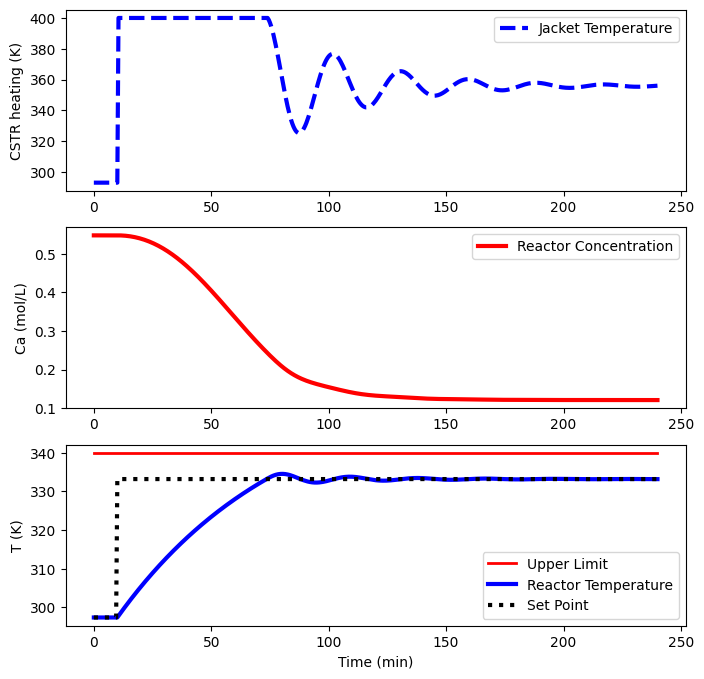

In [14]:
#CSTR Temperature control PI
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.optimize import fsolve
from simple_pid import PID

#CSTR model data from DWSIMS
def cstr (x,t,u,Tf,Caf):
  Tj = u #jacket temperature
  Ca = x[0]
  T = x[1] #Concentration and temperature in x matrix
  #parameters
  q = 0.006 #volumetric flowrate (m^3/s)
  V = 60 #volume of reactor (m^3)
  rho = 2575.74 #feed density (kg/m^3)
  Cp = 2193.73 #feed heat capacity (J/kg-k)
  delH = 31087.66 #heat of reaction (J/mol)
  EoverR = 6013.58 #Activation energy / Rconstant
  k0 = 5e4 #preexponential factor (1/s)
  UA = 44943 # heat transfer coeff * Area(W/K)
  rA = k0*np.exp(-EoverR/T)*Ca # reaction rate

  dCadt = q/V*(Caf - Ca) - rA

  dTdt = q/V*(Tf - T) \
            + delH/(rho*Cp)*rA \
            + UA/V/rho/Cp*(Tj-T)

  xdot = np.zeros(2)
  xdot[0] = dCadt
  xdot[1] = dTdt
  return xdot

#initial conditions at steady state
u_ss = 293.15
Tf = 303
Caf = 1 #feed concentration (of limiting reagent Co(OH)2)

#steady state is calculated from the model, so it stays correct when V changes
Ca_ss, T_ss = fsolve(lambda x: cstr(x, 0, u_ss, Tf, Caf), [0.5, 297.0])
x_0 = np.empty(2)
x_0[0] = Ca_ss
x_0[1] = T_ss


dt = 30.0
t = np.arange(0, 4*3600 + dt, dt) #in seconds at 30sec steps

#for plot
Ca = np.ones(len(t)) * Ca_ss
T  = np.ones(len(t)) * T_ss
u = np.ones(len(t)) * u_ss
sp = np.ones(len(t)) * T_ss #temperature setpoint  (CHANGED: same length as t)
sp[t >= 600] = 333.2        #step up unit
u_bias = u_ss

#PI controller parameter
Kc = 5.0
Ki = 0.1
Kd = 0.0
pid = PID(Kc,Ki,Kd)
oplo = 270.0
ophi = 400.0
pid.output_limits = (oplo-u_bias, ophi-u_bias)
pid.sample_time = None

#Cstr Simulation
for i in range(len(t)-1):
  pid.setpoint= sp[i]
  u[i+1] = pid(T[i], dt=dt) + u_bias   # CHANGED: pass dt
  ts = [t[i],t[i+1]]
  y = odeint(cstr,x_0,ts, args=(u[i+1], Tf, Caf))
  Ca[i+1] = y[-1][0]
  T[i+1] = y[-1][1]
  x_0[0] = Ca[i+1]
  x_0[1] = T[i+1]

#result plot
tmin = t/60
plt.figure(1, figsize=(8,8))
plt.subplot(3,1,1)
plt.plot(tmin,u,'b--',linewidth=3)
plt.ylabel('CSTR heating (K)')
plt.legend(['Jacket Temperature'],loc='best')

plt.subplot(3,1,2)
plt.plot(tmin,Ca,'r-',linewidth=3)
plt.ylabel('Ca (mol/L)')
plt.legend(['Reactor Concentration'],loc='best')

plt.subplot(3,1,3)
plt.plot([tmin[0],tmin[-1]],[340.0,340.0],'r-',linewidth=2)
plt.plot(tmin,T,'b-',linewidth=3)
plt.plot(tmin,sp,'k:',linewidth=3)
plt.ylabel('T (K)')
plt.xlabel('Time (min)')
plt.legend(['Upper Limit','Reactor Temperature','Set Point'],loc='best')
plt.show()

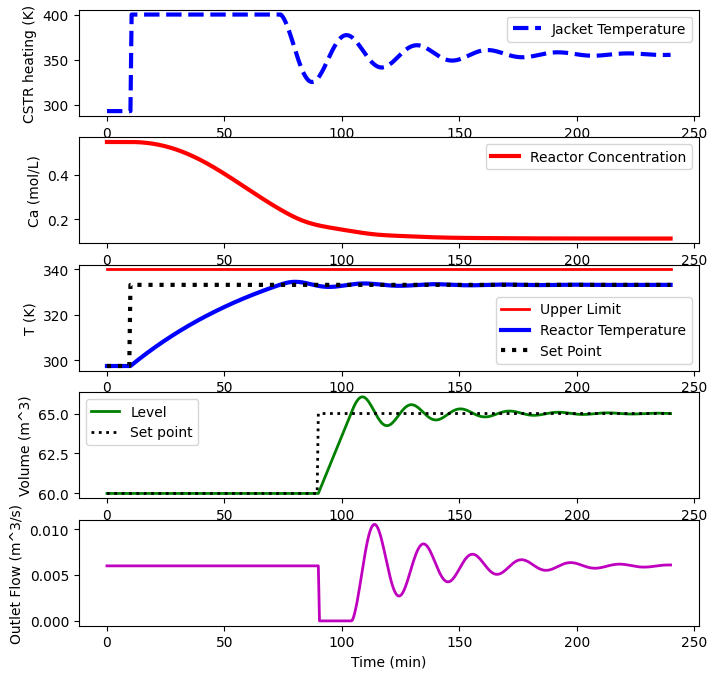

In [36]:
#CSTR Temperature and Level control PI
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.optimize import fsolve
from simple_pid import PID

#CSTR model data from DWSIMS
def cstr (x,t,u,Tf,q_out,Caf):
  Tj = u #jacket temperature
  Ca = x[0]
  T = x[1]
  V = x[2]#Concentration, volume and temperature in x matrix
  #parameters
  q = 0.006 #volumetric flowrate in (m^3/s)
  rho = 2575.74 #feed density (kg/m^3)
  Cp = 2193.73 #feed heat capacity (J/kg-k)
  delH = 31087.66 #heat of reaction (J/mol)
  EoverR = 6013.58 #Activation energy / Rconstant
  k0 = 5e4 #preexponential factor (1/s)
  UA = 44943 # heat transfer coeff * Area(W/K)
  rA = k0*np.exp(-EoverR/T)*Ca # reaction rate

  dCadt = q/V*(Caf - Ca) - rA

  dTdt = q/V*(Tf - T) \
            + delH/(rho*Cp)*rA \
            + UA/V/rho/Cp*(Tj-T)
  dVdt = q - q_out

  xdot = np.zeros(3)
  xdot[0] = dCadt
  xdot[1] = dTdt
  xdot[2] = dVdt
  return xdot

#initial conditions at steady state
u_ss = 293.15
q = 0.006
Tf = 303
Caf = 1 #feed concentration (of limiting reagent Co(OH)2)

#steady state is calculated from the model, so it stays correct when V changes
V_ss = 60
q_out = 0.006                   # at steady state, outlet flow = inlet flow
Ca_ss, T_ss = fsolve(lambda z: cstr([z[0], z[1], V_ss], 0, u_ss, Tf, q_out, Caf)[:2], [0.5, 297.0])
x_0 = np.empty(3)
x_0[0] = Ca_ss
x_0[1] = T_ss
x_0[2] = V_ss

dt = 30.0
t = np.arange(0, 4*3600 + dt, dt) #in seconds at 30sec steps

#for plot
Ca = np.ones(len(t)) * Ca_ss
T  = np.ones(len(t)) * T_ss
u = np.ones(len(t)) * u_ss
V = np.ones(len(t)) * V_ss
q_out = np.ones(len(t)) * q
sp_T = np.ones(len(t)) * T_ss #temperature setpoint  (CHANGED: same length as t)
sp_V = np.ones(len(t)) * V_ss
sp_T[t >= 600] = 333.2        #step up unit
sp_V[t >= 5400] = 65.0
u_bias = u_ss

#PI controller parameter
Kc = 5.0
Ki = 0.1
Kd = 0.0
pid = PID(Kc,Ki,Kd)
oplo = 270.0
ophi = 400.0
pid.output_limits = (oplo-u_bias, ophi-u_bias)
pid.sample_time = None

#PI control for Levels
KcL = 0.001
KiL = 0.000025
pid_L = PID(-KcL, -KiL, 0.0)
pid_L.output_limits = (0.0-q, 0.012-q)
pid_L.sample_time = None

#Cstr Simulation
for i in range(len(t)-1):
  pid.setpoint= sp_T[i]
  pid_L.setpoint = sp_V[i]
  u[i+1] = pid(T[i], dt=dt) + u_bias
  q_out[i+1] = pid_L(V[i], dt=dt) + q
  ts = [t[i],t[i+1]]
  y = odeint(cstr,x_0,ts, args=(u[i+1], Tf, q_out[i+1], Caf))
  Ca[i+1] = y[-1][0]
  T[i+1] = y[-1][1]
  V[i+1] = y[-1][2]
  x_0[0] = Ca[i+1]
  x_0[1] = T[i+1]
  x_0[2] = V[i+1]

#result plot
tmin = t/60
plt.figure(1, figsize=(8,8))
plt.subplot(5,1,1)
plt.plot(tmin,u,'b--',linewidth=3)
plt.ylabel('CSTR heating (K)')
plt.legend(['Jacket Temperature'],loc='best')

plt.subplot(5,1,2)
plt.plot(tmin,Ca,'r-',linewidth=3)
plt.ylabel('Ca (mol/L)')
plt.legend(['Reactor Concentration'],loc='best')

plt.subplot(5,1,3)
plt.plot([tmin[0],tmin[-1]],[340.0,340.0],'r-',linewidth=2)
plt.plot(tmin,T,'b-',linewidth=3)
plt.plot(tmin,sp_T,'k:',linewidth=3)
plt.ylabel('T (K)')
plt.legend(['Upper Limit','Reactor Temperature','Set Point'],loc='best')

plt.subplot(5,1,4)
plt.plot(tmin, V, 'g-', linewidth=2)
plt.plot(tmin,sp_V,'k:',linewidth=2)
plt.ylabel('Volume (m^3)')
plt.legend(['Level', 'Set point'], loc='best')

plt.subplot(5,1,5)
plt.plot(tmin, q_out, 'm-', linewidth=2)
plt.ylabel('Outlet Flow (m^3/s)')
plt.xlabel('Time (min)')
plt.show()